Library import 

In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 


csv_file import

In [5]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\Customer_Purchase_Prediction (1).csv")

In [6]:
df.head()

,customer_unique_id,total_orders,total_spent,avg_order_value,avg_review,avg_delivery_days,avg_price,total_items,will_repurchase,is_high_value
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,141.90,5.0,6.0,129.90,1,0,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,27.19,4.0,3.0,18.90,1,0,0
2,0000f46a3911fa3c0805444483337064,1,86.22,86.22,3.0,25.0,69.00,1,0,0
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,43.62,4.0,20.0,25.99,1,0,0
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,196.89,5.0,13.0,180.00,1,0,1


see data

In [7]:
df.shape

(93358, 10)

see columns

In [8]:
df.columns

Index(['customer_unique_id', 'total_orders', 'total_spent', 'avg_order_value',
       'avg_review', 'avg_delivery_days', 'avg_price', 'total_items',
       'will_repurchase', 'is_high_value'],
      dtype='str')

data information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_unique_id  93358 non-null  str    
 1   total_orders        93358 non-null  int64  
 2   total_spent         93358 non-null  float64
 3   avg_order_value     93358 non-null  float64
 4   avg_review          93358 non-null  float64
 5   avg_delivery_days   93358 non-null  float64
 6   avg_price           93358 non-null  float64
 7   total_items         93358 non-null  int64  
 8   will_repurchase     93358 non-null  int64  
 9   is_high_value       93358 non-null  int64  
dtypes: float64(5), int64(4), str(1)
memory usage: 10.0 MB


In [10]:
df.isnull().sum()

customer_unique_id    0
total_orders          0
total_spent           0
avg_order_value       0
avg_review            0
avg_delivery_days     0
avg_price             0
total_items           0
will_repurchase       0
is_high_value         0
dtype: int64

statical info

df.describe

check the target

In [11]:
df['will_repurchase'].value_counts().value_counts(normalize=True) * 100


count
90557    50.0
2801     50.0
Name: proportion, dtype: float64

target graph

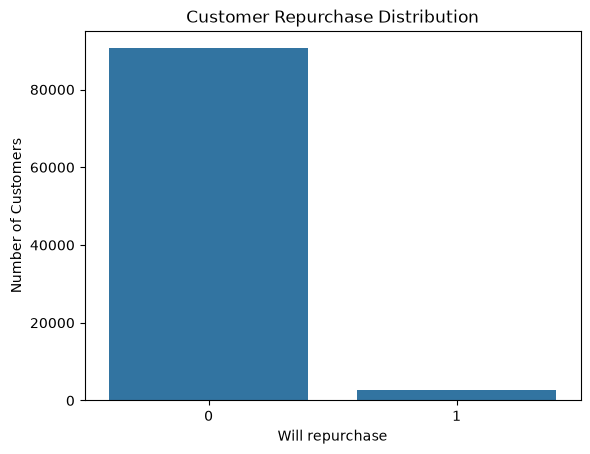

In [12]:
sns.countplot(x='will_repurchase', data=df)
plt.title("Customer Repurchase Distribution")
plt.xlabel("Will repurchase")
plt.ylabel("Number of Customers")
plt.show()

find important problem

In [13]:
pd.crosstab(df['total_orders'], df['will_repurchase'])

will_repurchase,0,1
total_orders,,
1,90557,0
2,0,2573
3,0,181
4,0,28
5,0,9
6,0,5
7,0,3
9,0,1
15,0,1


seprate featrure and target

In [14]:
X = df[
[
    'total_spent',
    'avg_order_value',
    'avg_review',
    'avg_delivery_days',
    'avg_price',
    'total_items',
    'is_high_value',
]
]
y = df['will_repurchase']

train test split

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

feature sclaing

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_tast_scaled = scaler.transform(X_test)

Logistic Regression model

In [30]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

prediction

In [35]:
y_pred = model.predict(X_test_scaled)

print(y_pred)

[1 1 0 ... 0 0 0]


Accuracy

In [37]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9067587832047986


Classification report

In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.90      0.95     18112
           1       0.24      1.00      0.39       560

    accuracy                           0.91     18672
   macro avg       0.62      0.95      0.67     18672
weighted avg       0.98      0.91      0.93     18672



Confusion Matrix

In [43]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[16372  1740]
 [    1   559]]


Graph

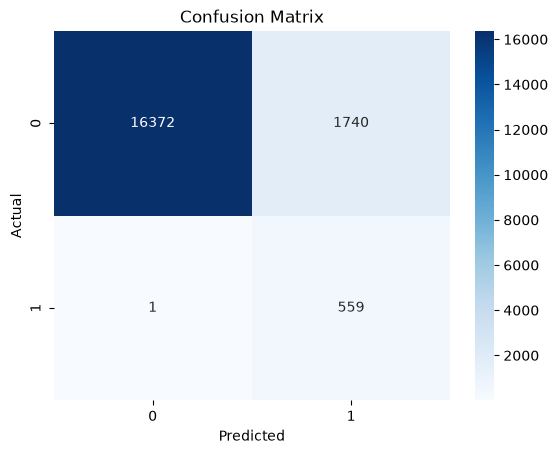

In [44]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [45]:
from sklearn.metrics import roc_auc_score
y_probability = model.predict_proba(X_test_scaled)[:, 1]
auc = roc_auc_score(y_test, y_probability)
print("ROC-AUC:", auc)

ROC-AUC: 0.9656089293601716


Try Random Forest Classifier

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [48]:
rf_pred = rf_model.predict(X_test)

In [49]:
rf_pred = rf_model.predict(X_test)

In [50]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.924057412167952


Future Importance

In [51]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(ascending=False)

print(importance)


total_items          0.627221
total_spent          0.162816
avg_order_value      0.066565
is_high_value        0.057824
avg_price            0.053865
avg_review           0.018714
avg_delivery_days    0.012995
dtype: float64


Graph

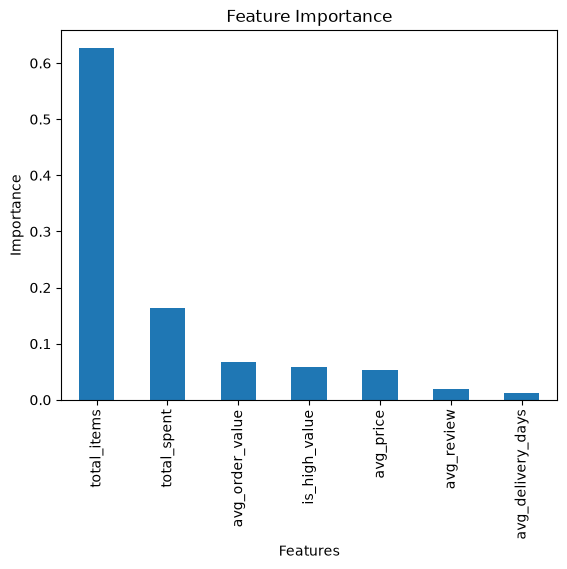

In [52]:
importance.plot(kind='bar')
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

New Customer Prediction

In [66]:
new_customer = pd.DataFrame({
    'total_spent': [500],
    'avg_order_value': [150],
    'avg_review': [4.5],
    'avg_delivery_days': [8],
    'avg_price': [120],
    'total_items': [4],
    'is_high_value': [1]
})

In [54]:
prediction = rf_model.predict(new_customer)
print(prediction)

[1]


In [55]:
probability = rf_model.predict_proba(new_customer)

print(probability)

[[0.02295322 0.97704678]]


Save Model

In [56]:
import joblib
joblib.dump(rf_model,"customer_repurchase_model.pkl")
joblib.dump(rf_model,"customer_scaler.pkl")

['customer_scaler.pkl']

In [58]:
model = joblib.load("customer_repurchase_model.pkl")